
## Iteration 1: Data Load

In this first iteration, you will load the dataset containing text samples labeled with three sentiment categories: positive, neutral, and negative. Using `pandas`, load the `Train.csv` and `Test.csv` datasets into DataFrames. Inspect the distribution of these three categories to understand how balanced the dataset is.


In [8]:
# Let's first load the datasets to understand their structure and content before solving the lab step by step.
import pandas as pd

# Load the datasets
train_path = 'Train.csv'
test_path = 'Test.csv'

train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)

# Display the first few rows of each dataset to understand the structure
train_data.head(), test_data.head()

(   Id                                               Body Sentiment Type
 0   1  rule 2 no metes about polarizing political top...        neutral
 1   2                                                NaN        neutral
 2   3  no politics danger now i can make a propaganda...       negative
 3   4                       i am the senate gets stabbed        neutral
 4   5                                  is this a suicide        neutral,
    Id                                               Body
 0   1  rule 2 no metes about polarizing political top...
 1   2                                                NaN
 2   3  no politics danger now i can make a propaganda...
 3   4                       i am the senate gets stabbed
 4   5                                  is this a suicide)


## Iteration 2: Data Exploration

Explore the dataset to understand the sentiment distribution and other key features. First, visualize the distribution of the sentiment labels—positive, neutral, and negative—to check for any class imbalance. Additionally, examine the length of the text samples and generate word clouds for each class.


In [11]:
# Iteration 2: Data Exploration

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the distribution of sentiment labels in the training set
sns.countplot(x='Sentiment Type', data=train_data)
plt.title('Distribution of Sentiment Labels')
plt.show()

# Handle missing values in the 'Body' column
train_data['Body'] = train_data['Body'].fillna('')
test_data['Body'] = test_data['Body'].fillna('')

# Check the distribution of text lengths in the training dataset
train_data['text_length'] = train_data['Body'].apply(lambda x: len(x.split()))

# Visualize the distribution of text lengths
sns.histplot(train_data['text_length'], bins=30)
plt.title('Distribution of Text Length')
plt.show()

# Display summary statistics about the text lengths
train_data['text_length'].describe()

ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

### Word Cloud for Feature Understanding

Before moving forward with tokenization, we can generate word clouds for each sentiment category to further understand the patterns in the text data. This visualization will help us get a sense of the most common words used in positive, neutral, and negative reviews, which might give us clues about how the model will differentiate between sentiments.

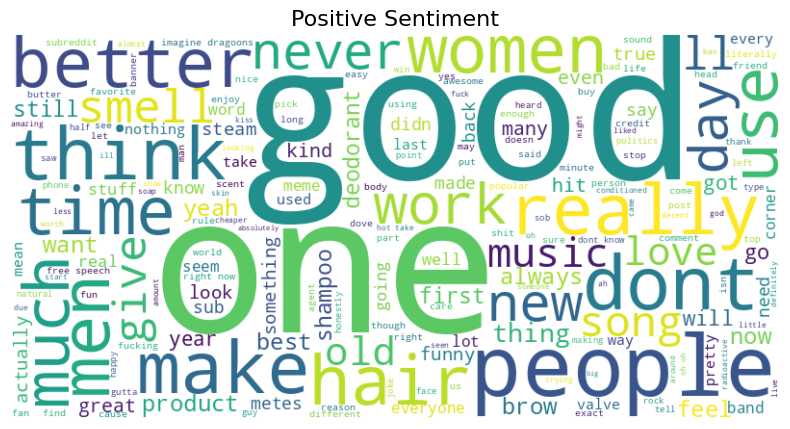

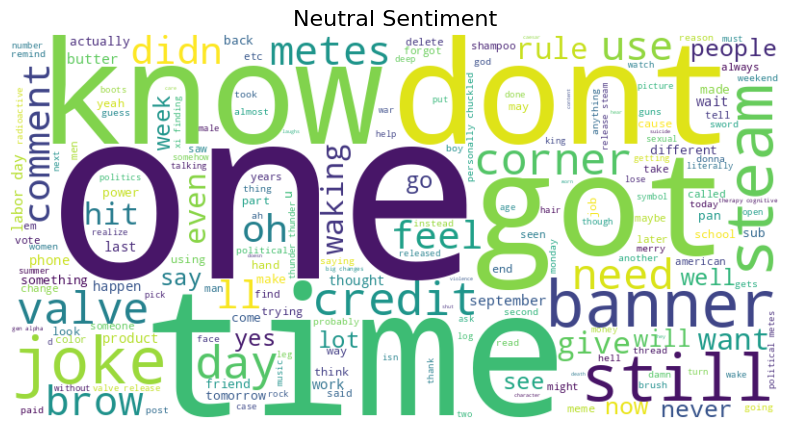

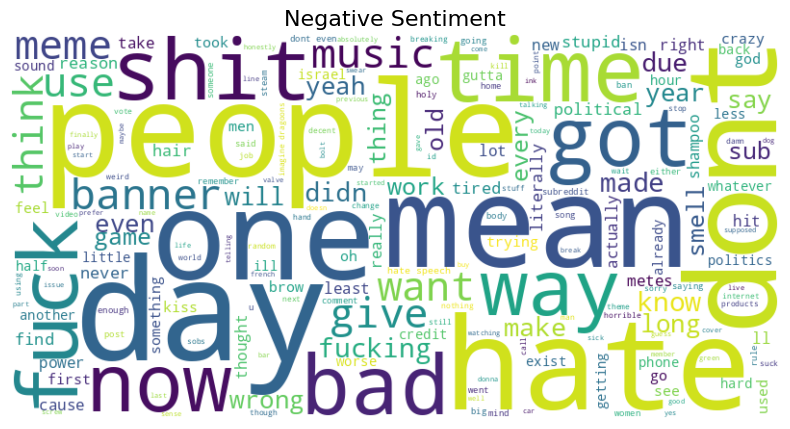

In [13]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Function to generate word cloud
def generate_wordcloud(text, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(title, fontsize=16)
    plt.show()

# Generate word clouds for each sentiment type
positive_text = " ".join(train_data[train_data['Sentiment Type'] == 'positive']['Body'].dropna())
neutral_text = " ".join(train_data[train_data['Sentiment Type'] == 'neutral']['Body'].dropna())
negative_text = " ".join(train_data[train_data['Sentiment Type'] == 'negative']['Body'].dropna())

# Show the word clouds
generate_wordcloud(positive_text, 'Positive Sentiment')
generate_wordcloud(neutral_text, 'Neutral Sentiment')
generate_wordcloud(negative_text, 'Negative Sentiment')


## Iteration 3: Feature Preprocessing

For the model to handle three-class classification, you need to preprocess the text data. Use a pre-trained Hugging Face tokenizer (in this case, `AutoTokenizer` for the **DistilBERT** model) to convert the raw text into tokenized sequences that the model can process. Ensure that the labels are correctly encoded into three distinct categories. After tokenization, pad and truncate the sequences to maintain a consistent input size for the model. Finally, split the data into training, validation, and test sets.

### Libraries to use:
- `transformers` (AutoTokenizer)
- `sklearn` (train_test_split)

### Hints:
- Use the `AutoTokenizer` class to convert text into input tokens.
- Ensure the text sequences are padded to a consistent length.


In [17]:
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split
import tensorflow as tf

# Initialize the DistilBERT tokenizer
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

# Function to tokenize the text data
def tokenize_data(data, tokenizer):
    return tokenizer(
        list(data['Body']),  # We use the 'Body' column for tokenization
        padding=True, 
        truncation=True, 
        max_length=128, 
        return_tensors='tf'  # Return the output as TensorFlow tensors
    )

# Tokenize the train dataset
train_encodings = tokenize_data(train_data, tokenizer)

# Tokenize the test dataset (without labels since they do not exist in test_data)
# test_encodings = tokenize_data(test_data, tokenizer)


# Convert sentiment labels to integers (0 = negative, 1 = neutral, 2 = positive) in train_data
train_labels = train_data['Sentiment Type'].map({'negative': 0, 'neutral': 1, 'positive': 2})

# Add the labels to the encoded data (only for the training set)
train_encodings['labels'] = tf.convert_to_tensor(train_labels.values)


# Convert the TensorFlow tensors to NumPy arrays
X_input_ids = train_encodings['input_ids'].numpy()  # Convert input_ids to NumPy
y_labels = train_encodings['labels'].numpy()  # Convert labels to NumPy

# Split the training data into training and validation sets (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(X_input_ids, y_labels, test_size=0.2, random_state=42)

# Check the shapes of the resulting datasets
print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_val:", X_val.shape)
print("Tamaño de y_train:", y_train.shape)
print("Tamaño de y_val:", y_val.shape)
print("Tamaño de y_val:", X_input_ids)

# Optional: Tokenized test data is ready for predictions or evaluations without labels



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/adrian/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/home/adrian/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/home/adrian/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/home/adrian

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import


## Iteration 4: Load a Pre-trained Model

In this step, you will load a pre-trained **DistilBERT** model that can handle multi-class classification. Configure the model to output three classes (positive, neutral, and negative). Use `TFDistilBertForSequenceClassification`, a model designed for text classification tasks. Set `num_labels=3` to handle three classes.

### Libraries to use:
- `transformers` (TFDistilBertForSequenceClassification)

### Hints:
- When loading the model, specify the number of labels as `3`.


In [ ]:
from transformers import TFDistilBertForSequenceClassification
import tensorflow as tf

# Cargar el modelo DistilBERT preentrenado para clasificación de secuencias con 3 etiquetas
model = TFDistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=3)

# Compilar el modelo con el optimizador y la función de pérdida
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

# Mostrar el resumen del modelo para verificar la arquitectura
model.summary()


## Iteration 5: Fine-tune the Pre-trained Model

Fine-tune the pre-trained model on your dataset to adjust it for three-class sentiment classification. Use the TensorFlow/Keras training loop instead of Hugging Face’s `Trainer` API. During training, monitor key metrics such as loss and accuracy for all three classes.

### Libraries to use:
- `tensorflow`

### Hints:
- Compile the model with an optimizer, loss function (categorical cross-entropy), and accuracy metrics.
- Train the model using the `fit()` function and monitor the accuracy and loss over a few epochs.


In [ ]:
# Convert the tokenized data to TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train)).batch(8)
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(8)

# Fine-tune the model for 1 epochs
model.fit(train_dataset, validation_data=val_dataset, epochs=5)


## Iteration 6: Model Evaluation

Evaluate the fine-tuned model’s performance on the test dataset. Generate predictions for the three sentiment classes (positive, neutral, negative) and compare them to the true labels. Use metrics such as accuracy, precision, recall, and F1-score for each class. Also, generate a confusion matrix to visualize the model’s ability to distinguish between the sentiments.

### Libraries to use:
- `sklearn` (accuracy_score, precision_recall_fscore_support, confusion_matrix)
- `seaborn` (for plotting the confusion matrix)

### Hints:
- Use the `predict()` method to generate predictions.
- Calculate evaluation metrics (precision, recall, F1-score) using `sklearn`.
- Plot the confusion matrix using `seaborn`.


In [ ]:
# Make predictions with test dataset
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
train_data['Sentiment Encoded'] = label_encoder.fit_transform(train_data['Sentiment Type'])

# Tokenize the test data
test_encodings = tokenize_data(test_data, tokenizer)
test_dataset = tf.data.Dataset.from_tensor_slices(test_encodings['input_ids']).batch(16)
print(test_dataset)
# Convert the test encodings to a TensorFlow dataset
#test_encodings1 = tokenizer(test_data['Body'].fillna('').tolist(), truncation=True, padding=True, max_length=128)
#test_dataset1 = tf.data.Dataset.from_tensor_slices(test_encodings['input_ids']).batch(16)

# Make predictions on the test set
predictions = model.predict(test_dataset).logits
predicted_labels = tf.argmax(predictions, axis=1).numpy()

# Convert the predicted labels back to sentiment labels
predicted_sentiments = label_encoder.inverse_transform(predicted_labels)

# Display a few test predictions
for i in range(5):
    print(f"Text: {test_data['Body'][i]}")
    print(f"Predicted Sentiment: {predicted_sentiments[i]}")
    print("---")

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# We predict on the validation set.
predictions = model.predict(val_dataset).logits
predicted_labels = tf.argmax(predictions, axis=1).numpy()

# Classification Report
print("Classification Report:")
print(classification_report(y_val, predicted_labels, target_names=['Negative', 'Neutral', 'Positive']))
# Confusion Matrix
conf_matrix = confusion_matrix(y_val, predicted_labels)

# Visualizar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()



## Iteration 7: Save and Load the Model

Once you are satisfied with the model’s performance, save both the fine-tuned model and tokenizer using Hugging Face’s `save_pretrained()` method. Demonstrate how to load the saved model and tokenizer later.

### Libraries to use:
- `transformers` (save_pretrained, from_pretrained)

### Hints:
- Use the `save_pretrained()` method to store the model and tokenizer.
- Demonstrate loading the saved model using `from_pretrained()`.


In [ ]:
# Save the fine-tuned model and tokenizer
model.save_pretrained('./sentiment_model')
tokenizer.save_pretrained('./sentiment_tokenizer')

# Load the model and tokenizer
loaded_model = TFDistilBertForSequenceClassification.from_pretrained('./sentiment_model')
loaded_tokenizer = AutoTokenizer.from_pretrained('./sentiment_tokenizer')

## Iteration 8: Custom Predictions

In this section, you will test the model with your own comments, rather than the test set data. This gives us an opportunity to see how well the model generalizes to new, unseen data that you can create.

You can replace the default comments with your own text, and the model will predict whether each comment expresses a positive, neutral, or negative sentiment. 

This exercise helps us understand how the fine-tuned model behaves when faced with real-world input data and further validates its performance beyond the dataset we trained and tested on.

In [ ]:
# Define custom comments (you can modify these with their own text)

custom_comments = [
    # Positive comments
    "This product really works well, and I love how it makes my day better.",
    "I think this is one of the best purchases I've made; it smells amazing!",
    "I absolutely love the way this product makes me feel; it's so good!",
    
    # Neutral comments
    "It's okay, but nothing really stands out to me.",
    "The product works fine, but I don’t see anything particularly special about it.",
    "I think it’s decent, but I don’t feel strongly one way or the other.",
    
    # Negative comments
    "I hate how it didn’t work as expected and just wasted my time.",
    "This product is so bad, it broke after just one use!",
    "I’m really disappointed, the quality is horrible and I feel like I wasted my money."
]



# Tokenize the custom input
custom_encodings = tokenizer(custom_comments, truncation=True, padding=True, max_length=128, return_tensors='tf')

# Make predictions using the fine-tuned model
custom_predictions = model.predict(custom_encodings['input_ids'])

# Convert the logits to label predictions
custom_predicted_labels = tf.argmax(custom_predictions.logits, axis=1)

# Map numerical labels back to sentiment categories
label_map = {0: "negative", 1: "neutral", 2: "positive"}
predicted_sentiments = [label_map[label] for label in custom_predicted_labels.numpy()]

# Display the results
for comment, sentiment in zip(custom_comments, predicted_sentiments):
    print(f'Comment: "{comment}"')
    print(f'Predicted Sentiment: {sentiment}')
    print('-'*50)


## Bonus: Handling Class Imbalance

The dataset is imbalanced, with more positive examples than negative or neutral ones. You will explore two methods to handle this imbalance:

### Option 1: Class Weights
Assign different weights to each class during training to balance the representation. TensorFlow’s `class_weight` parameter helps distribute weights to adjust for class imbalance.

[TensorFlow Documentation - Class Weights](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data?hl=es-419)

### Option 2: Data Augmentation
Augment the data for the minority classes by generating new text samples. You can use techniques such as synonym replacement to create new variations of the minority class samples.

[TensorFlow Documentation - Data Augmentation](https://www.tensorflow.org/tutorials/images/data_augmentation?hl=es-419)

[Neptune.ai - Data Augmentation](https://neptune.ai/blog/data-augmentation-nlp)

### Hints:
- For **class weights**, use the `class_weight` argument in `model.fit()`.
- For **data augmentation**, you can use libraries such as `nltk` to replace words with synonyms.
